Install and Imports

In [1]:
import os, json
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Patch

print("Ready.")

Ready.


Verify Input Paths

In [2]:
print("=== Available inputs ===")
for entry in sorted(os.listdir("/kaggle/input")):
    print(f"  /kaggle/input/{entry}")
    subdir = f"/kaggle/input/{entry}"
    if os.path.isdir(subdir):
        for f in sorted(os.listdir(subdir))[:5]:
            print(f"      {f}")

=== Available inputs ===
  /kaggle/input/datasets
      yeamins
  /kaggle/input/notebooks
      mahmudsaleh
      yeamins


Load all results

In [3]:
RESULT_PATHS = {
    "Part A (YOLOv26)": "/kaggle/input/notebooks/yeamins/notebook3/results_yolov26.json",
    "SimCLR":           "/kaggle/input/notebooks/yeamins/plaque-simclr/results_simclr.json",
    "BYOL":             "/kaggle/input/notebooks/yeamins/plaque-byol/results_byol.json",
    "MAE":              "/kaggle/input/notebooks/mahmudsaleh/plaque-mae-downstream/results_mae.json",
    "DINOv2":           "/kaggle/input/notebooks/mahmudsaleh/plaque-dinov2-downstream/results_dinov2.json",
}

results = {}
for name, path in RESULT_PATHS.items():
    if not os.path.exists(path):
        print(f"⚠️  MISSING: {name} at {path}")
        continue
    with open(path) as f:
        results[name] = json.load(f)
    print(f"✓ Loaded: {name}")

print(f"\nTotal methods loaded: {len(results)}")

✓ Loaded: Part A (YOLOv26)
✓ Loaded: SimCLR
✓ Loaded: BYOL
✓ Loaded: MAE
✓ Loaded: DINOv2

Total methods loaded: 5


Load Part A split

In [4]:
SPLIT_PATH = "/kaggle/input/notebooks/yeamins/438-assignment-a/split.json"
with open(SPLIT_PATH) as f:
    split = json.load(f)

N_TRAIN = len(split["train"])   
N_VAL   = len(split["val"])     
N_TEST  = len(split["test"])  
MASK_THRESHOLD = split["mask_threshold"]

print(f"Train (unlabeled pretraining): {N_TRAIN} images")
print(f"Val (labeled fine-tune):       {N_VAL} images  ← what SSL methods used for labels")
print(f"Test (eval):                   {N_TEST} images")
print(f"\nLabel-efficiency ratio: SSL used {N_VAL}/{N_TRAIN} = {N_VAL/N_TRAIN:.1%} of Part A's labeled data")

Train (unlabeled pretraining): 416 images
Val (labeled fine-tune):       73 images  ← what SSL methods used for labels
Test (eval):                   48 images

Label-efficiency ratio: SSL used 73/416 = 17.5% of Part A's labeled data


Label-efficiency comparison table

In [5]:
def extract_metrics(name, r):
    tm = r["test_metrics"]

    if name == "Part A (YOLOv26)":
        labels_used = r.get("labeled_images_used", N_TRAIN)
        method_class = "Supervised baseline"
    else:
        labels_used = r.get("labeled_images_used", N_VAL)
        method_class = "SSL + fine-tune"

    if "iou_per_class" in tm:                      
        iou_bg     = tm["iou_per_class"][0]
        iou_plaque = tm["iou_per_class"][1]
        dice_plaque = tm["dice_per_class"][1]
    else:                                           
        iou_bg     = tm["iou_background"]
        iou_plaque = tm["iou_plaque"]
        dice_plaque = tm["dice_plaque"]

    return {
        "Method": name,
        "Class": method_class,
        "Backbone": r.get("backbone", "-"),
        "Labeled imgs": labels_used,
        "Label ratio vs Part A": f"{labels_used/N_TRAIN:.1%}",
        "Test mIoU": tm["mIoU"],
        "IoU (bg)": iou_bg,
        "IoU (plaque)": iou_plaque,
        "Mean Dice": tm["mean_dice"],
        "Dice (plaque)": dice_plaque,
        "Pixel accuracy": tm["overall_pixel_acc"],
    }

rows = [extract_metrics(name, r) for name, r in results.items()]
df = pd.DataFrame(rows)

# Round for display
display_df = df.copy()
for col in ["Test mIoU", "IoU (bg)", "IoU (plaque)", "Mean Dice", "Dice (plaque)", "Pixel accuracy"]:
    display_df[col] = display_df[col].map(lambda v: f"{v:.4f}")

print(display_df.to_string(index=False))
df.to_csv("/kaggle/working/comparison_table.csv", index=False)

          Method               Class    Backbone  Labeled imgs Label ratio vs Part A Test mIoU IoU (bg) IoU (plaque) Mean Dice Dice (plaque) Pixel accuracy
Part A (YOLOv26) Supervised baseline           -           416                100.0%    0.7353   0.9933       0.4773    0.8214        0.6462         0.9934
          SimCLR     SSL + fine-tune   ResNet-50            73                 17.5%    0.6730   0.9923       0.3537    0.7593        0.5225         0.9923
            BYOL     SSL + fine-tune   ResNet-50            73                 17.5%    0.6566   0.9916       0.3216    0.7413        0.4867         0.9917
             MAE     SSL + fine-tune ViT-Base/16            73                 17.5%    0.5662   0.9901       0.1422    0.6220        0.2490         0.9901
          DINOv2     SSL + fine-tune    ViT-S/14            73                 17.5%    0.6458   0.9909       0.3008    0.7289        0.4624         0.9910


Label-efficiency ratios vs Part A

In [6]:
baseline = df[df["Method"] == "Part A (YOLOv26)"].iloc[0]
baseline_miou = baseline["Test mIoU"]
baseline_plaque_iou = baseline["IoU (plaque)"]
baseline_plaque_dice = baseline["Dice (plaque)"]

recovery_rows = []
for _, row in df.iterrows():
    if row["Method"] == "Part A (YOLOv26)":
        continue
    recovery_rows.append({
        "Method": row["Method"],
        "Test mIoU": f"{row['Test mIoU']:.4f}",
        "% of Part A mIoU": f"{100*row['Test mIoU']/baseline_miou:.1f}%",
        "Plaque IoU": f"{row['IoU (plaque)']:.4f}",
        "% of Part A plaque IoU": f"{100*row['IoU (plaque)']/baseline_plaque_iou:.1f}%",
        "Plaque Dice": f"{row['Dice (plaque)']:.4f}",
        "% of Part A plaque Dice": f"{100*row['Dice (plaque)']/baseline_plaque_dice:.1f}%",
        "Labels used": f"{int(row['Labeled imgs'])} ({row['Label ratio vs Part A']})",
    })

recovery_df = pd.DataFrame(recovery_rows)
print("=== Label-efficiency: SSL recovery of Part A's fully-supervised performance ===\n")
print(recovery_df.to_string(index=False))
recovery_df.to_csv("/kaggle/working/label_efficiency_table.csv", index=False)

=== Label-efficiency: SSL recovery of Part A's fully-supervised performance ===

Method Test mIoU % of Part A mIoU Plaque IoU % of Part A plaque IoU Plaque Dice % of Part A plaque Dice Labels used
SimCLR    0.6730            91.5%     0.3537                  74.1%      0.5225                   80.9%  73 (17.5%)
  BYOL    0.6566            89.3%     0.3216                  67.4%      0.4867                   75.3%  73 (17.5%)
   MAE    0.5662            77.0%     0.1422                  29.8%      0.2490                   38.5%  73 (17.5%)
DINOv2    0.6458            87.8%     0.3008                  63.0%      0.4624                   71.6%  73 (17.5%)


Comparison Chart

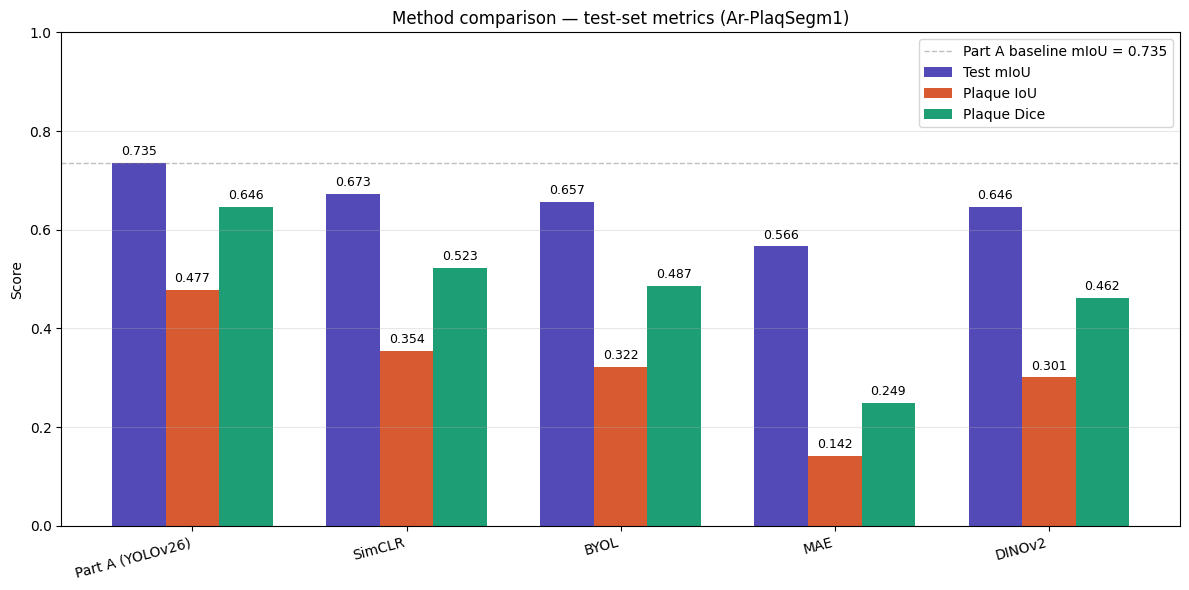

In [7]:
methods = df["Method"].tolist()
metrics = ["Test mIoU", "IoU (plaque)", "Dice (plaque)"]
metric_labels = ["Test mIoU", "Plaque IoU", "Plaque Dice"]

x = np.arange(len(methods))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))
colors = ["#534AB7", "#D85A30", "#1D9E75"]
for i, (metric, label, color) in enumerate(zip(metrics, metric_labels, colors)):
    values = df[metric].values
    bars = ax.bar(x + i*width, values, width, label=label, color=color)
    for bar, v in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f"{v:.3f}", ha="center", va="bottom", fontsize=9)

# Mark the Part A baseline mIoU as a horizontal reference line
ax.axhline(baseline_miou, color="gray", linestyle="--", linewidth=1, alpha=0.5,
           label=f"Part A baseline mIoU = {baseline_miou:.3f}")

ax.set_xticks(x + width)
ax.set_xticklabels(methods, rotation=15, ha="right")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.0)
ax.set_title("Method comparison — test-set metrics (Ar-PlaqSegm1)")
ax.legend(loc="upper right")
ax.grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig("/kaggle/working/comparison_chart.png", dpi=150, bbox_inches="tight")
plt.show()

Label-efficiency scatter plot

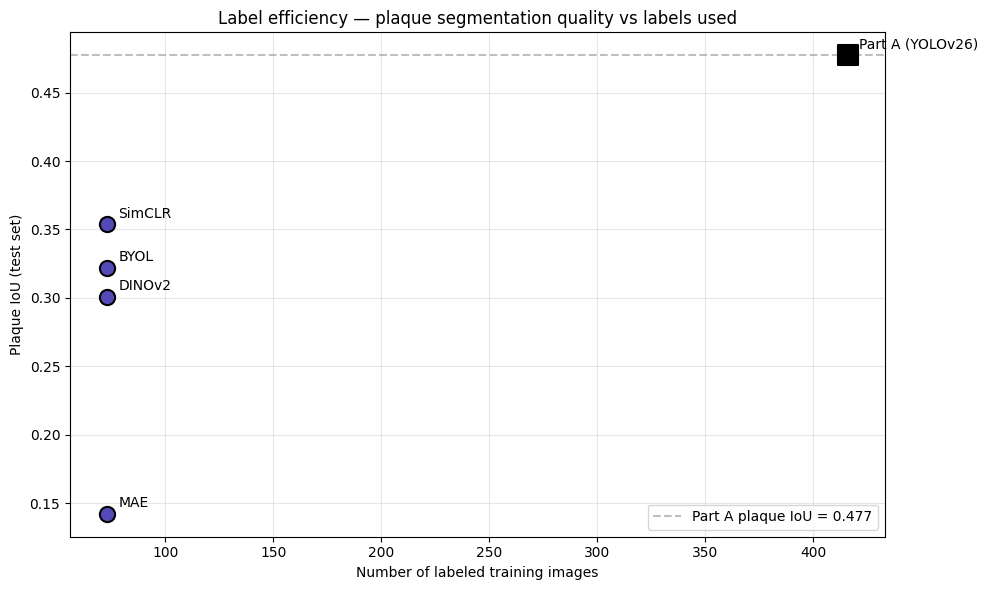

In [8]:
fig, ax = plt.subplots(figsize=(10, 6))

for _, row in df.iterrows():
    is_baseline = row["Method"] == "Part A (YOLOv26)"
    color = "#000000" if is_baseline else "#534AB7"
    marker = "s" if is_baseline else "o"
    size = 200 if is_baseline else 120
    ax.scatter(row["Labeled imgs"], row["IoU (plaque)"], s=size,
               color=color, marker=marker, edgecolor="black", linewidth=1.5, zorder=3)
    ax.annotate(row["Method"], (row["Labeled imgs"], row["IoU (plaque)"]),
                xytext=(8, 5), textcoords="offset points", fontsize=10)

ax.axhline(baseline_plaque_iou, color="gray", linestyle="--", alpha=0.5,
           label=f"Part A plaque IoU = {baseline_plaque_iou:.3f}")
ax.set_xlabel("Number of labeled training images")
ax.set_ylabel("Plaque IoU (test set)")
ax.set_title("Label efficiency — plaque segmentation quality vs labels used")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("/kaggle/working/label_efficiency_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

Consolidated per-image failure analysis

In [9]:
per_image_paths = {
    "SimCLR": "/kaggle/input/notebooks/yeamins/plaque-simclr/simclr_per_image.csv",
    "BYOL":   "/kaggle/input/notebooks/yeamins/plaque-byol/byol_per_image.csv",
    "MAE":    "/kaggle/input/notebooks/mahmudsaleh/plaque-mae-downstream/mae_per_image.csv",
    "DINOv2": "/kaggle/input/notebooks/mahmudsaleh/plaque-dinov2-downstream/dinov2_per_image.csv",
}

per_image_dfs = {}
for method, path in per_image_paths.items():
    if os.path.exists(path):
        d = pd.read_csv(path)
        d = d.rename(columns={"plaque_iou": f"{method}_plaque_iou"})
        per_image_dfs[method] = d[["idx", f"{method}_plaque_iou", "has_plaque"]]
        print(f"✓ Loaded per-image for {method}: {len(d)} rows")
    else:
        print(f"⚠️  MISSING per-image for {method}")

consolidated = None
for method, d in per_image_dfs.items():
    if consolidated is None:
        consolidated = d
    else:
        consolidated = consolidated.merge(d.drop(columns=["has_plaque"]), on="idx", how="outer")

plaque_only = consolidated[consolidated["has_plaque"] == 1].copy()

iou_cols = [c for c in plaque_only.columns if c.endswith("_plaque_iou")]
plaque_only["mean_iou"]   = plaque_only[iou_cols].mean(axis=1)
plaque_only["min_iou"]    = plaque_only[iou_cols].min(axis=1)
plaque_only["max_iou"]    = plaque_only[iou_cols].max(axis=1)
plaque_only["iou_spread"] = plaque_only["max_iou"] - plaque_only["min_iou"]

print(f"\nPlaque-positive test images: {len(plaque_only)}")
print(f"\n=== 10 hardest test images (lowest mean plaque IoU across all methods) ===")
print(plaque_only.nsmallest(10, "mean_iou")[["idx"] + iou_cols + ["mean_iou"]].to_string(index=False))

print(f"\n=== 10 most divergent images (largest IoU spread across methods) ===")
print(plaque_only.nlargest(10, "iou_spread")[["idx"] + iou_cols + ["iou_spread"]].to_string(index=False))

✓ Loaded per-image for SimCLR: 48 rows
✓ Loaded per-image for BYOL: 48 rows
✓ Loaded per-image for MAE: 48 rows
✓ Loaded per-image for DINOv2: 48 rows

Plaque-positive test images: 24

=== 10 hardest test images (lowest mean plaque IoU across all methods) ===
 idx  SimCLR_plaque_iou  BYOL_plaque_iou  MAE_plaque_iou  DINOv2_plaque_iou  mean_iou
 521           0.000000         0.000000        0.000000           0.000000  0.000000
 542           0.103524         0.152342        0.000000           0.046525  0.075598
 520           0.333744         0.000000        0.000000           0.049748  0.095873
 540           0.415057         0.057944        0.000000           0.000000  0.118250
 523           0.000000         0.000000        0.194779           0.279074  0.118463
 528           0.000000         0.269937        0.000000           0.259910  0.132462
 538           0.069127         0.125678        0.296154           0.118585  0.152386
 525           0.302256         0.174213        0.00

Failure overlap analysis

In [10]:
def worst_k_idx(df_col, k=10):
    return set(plaque_only.nsmallest(k, df_col)["idx"].astype(str))

worst_sets = {method: worst_k_idx(f"{method}_plaque_iou") for method in per_image_dfs.keys()}

print("=== Overlap of worst-10 failures across methods ===\n")
overlap_matrix = []
for m1 in worst_sets:
    row = []
    for m2 in worst_sets:
        row.append(len(worst_sets[m1] & worst_sets[m2]))
    overlap_matrix.append(row)

overlap_df = pd.DataFrame(overlap_matrix, index=worst_sets.keys(), columns=worst_sets.keys())
print(overlap_df)

common_failures = set.intersection(*worst_sets.values())
print(f"\n=== Images in worst-10 of EVERY SSL method ({len(common_failures)}) ===")
print(sorted(common_failures))

print(f"\nInterpretation: {len(common_failures)}/10 shared worst cases suggests these are intrinsically hard images (annotation ambiguity, low contrast, or small lesion size) — not model-specific failures.")

=== Overlap of worst-10 failures across methods ===

        SimCLR  BYOL  MAE  DINOv2
SimCLR      10     7    3       5
BYOL         7    10    4       7
MAE          3     4   10       6
DINOv2       5     7    6      10

=== Images in worst-10 of EVERY SSL method (2) ===
['521', '525']

Interpretation: 2/10 shared worst cases suggests these are intrinsically hard images (annotation ambiguity, low contrast, or small lesion size) — not model-specific failures.


Visualize consolidated worst cases

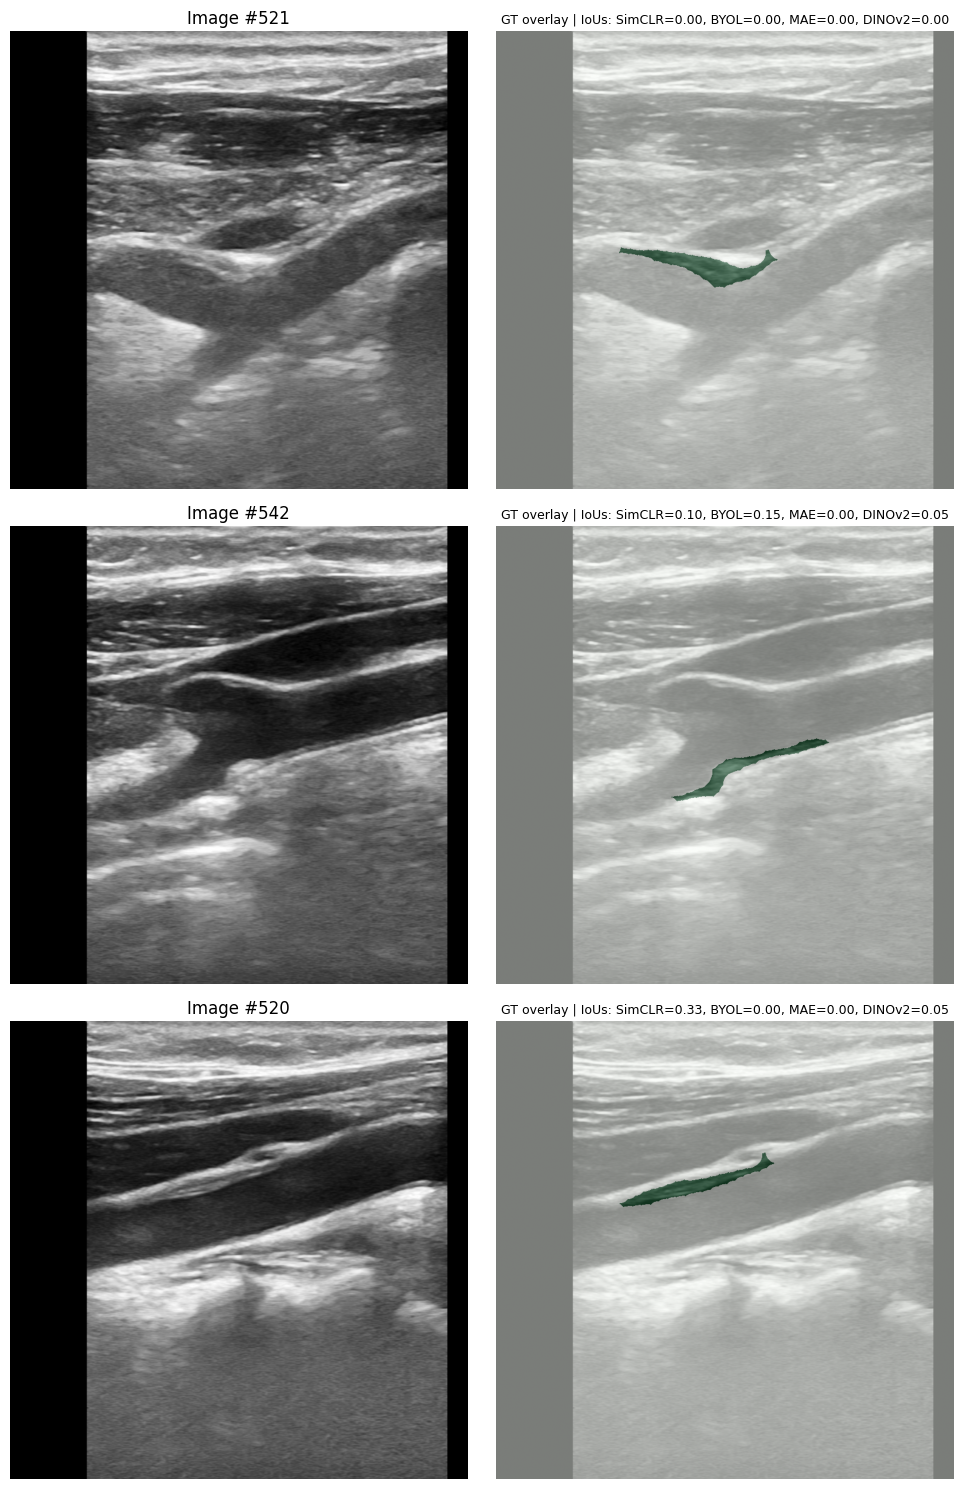

In [11]:
DATA_ROOT = "/kaggle/input/datasets/yeamins/ar-plaqsegm1-ultrasound-segmentation/Ar-PlaqSegm1 First Argentine database of B-mode ul"

def fix_paths(records, new_root):
    fixed = []
    for rec in records:
        r = rec.copy()
        for key in ["img_path", "mask_path"]:
            parts = r[key].replace("\\", "/").split("/")
            r[key] = os.path.join(new_root, parts[-2], parts[-1])
        fixed.append(r)
    return fixed

test_records = fix_paths(split["test"], DATA_ROOT)

if len(common_failures) >= 3:
    show_idx = sorted(common_failures)[:3]
else:
    show_idx = plaque_only.nsmallest(3, "mean_iou")["idx"].astype(str).tolist()

fig, axes = plt.subplots(len(show_idx), 2, figsize=(10, 5*len(show_idx)))
if len(show_idx) == 1:
    axes = axes.reshape(1, -1)

for row, idx in enumerate(show_idx):
    rec = next(r for r in test_records if str(r["idx"]) == str(idx))
    img = cv2.imread(rec["img_path"], cv2.IMREAD_GRAYSCALE)
    gt = (cv2.imread(rec["mask_path"], cv2.IMREAD_GRAYSCALE) > MASK_THRESHOLD).astype(np.uint8)

    axes[row, 0].imshow(img, cmap="gray")
    axes[row, 0].set_title(f"Image #{idx}")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(img, cmap="gray")
    axes[row, 1].imshow(gt, cmap="Greens", alpha=0.5)

    ious_this_img = plaque_only[plaque_only["idx"].astype(str) == str(idx)]
    if len(ious_this_img):
        row_data = ious_this_img.iloc[0]
        title = f"GT overlay | IoUs: "
        parts = []
        for m in per_image_dfs.keys():
            v = row_data.get(f"{m}_plaque_iou", None)
            if v is not None and not pd.isna(v):
                parts.append(f"{m}={v:.2f}")
        title += ", ".join(parts)
        axes[row, 1].set_title(title, fontsize=9)
    axes[row, 1].axis("off")

plt.tight_layout()
plt.savefig("/kaggle/working/consolidated_worst_cases.png", dpi=100, bbox_inches="tight")
plt.show()

Method ranking summary

In [12]:
print("=" * 70)
print(" FINAL RANKINGS ON Ar-PlaqSegm1 CAROTID PLAQUE SEGMENTATION")
print("=" * 70)

ssl_df = df[df["Method"] != "Part A (YOLOv26)"].copy()
ssl_df_ranked = ssl_df.sort_values("IoU (plaque)", ascending=False).reset_index(drop=True)

print(f"\n>>> Best fully-supervised (Part A baseline): YOLOv26 @ {baseline_plaque_iou:.4f} plaque IoU (291 labels)")
print(f"\n>>> SSL ranking by plaque IoU (all using {N_VAL} labels — {N_VAL/N_TRAIN:.1%} of Part A):\n")

for rank, (_, row) in enumerate(ssl_df_ranked.iterrows(), 1):
    recovery = 100 * row["IoU (plaque)"] / baseline_plaque_iou
    print(f"   {rank}. {row['Method']:12s} — plaque IoU {row['IoU (plaque)']:.4f}  ({recovery:.1f}% of baseline)")

best_ssl = ssl_df_ranked.iloc[0]
print(f"\n=== Key label-efficiency finding ===")
print(f"{best_ssl['Method']} recovered {100*best_ssl['IoU (plaque)']/baseline_plaque_iou:.1f}% "
      f"of Part A's plaque IoU using {100*N_VAL/N_TRAIN:.1f}% of the labels.")

 FINAL RANKINGS ON Ar-PlaqSegm1 CAROTID PLAQUE SEGMENTATION

>>> Best fully-supervised (Part A baseline): YOLOv26 @ 0.4773 plaque IoU (291 labels)

>>> SSL ranking by plaque IoU (all using 73 labels — 17.5% of Part A):

   1. SimCLR       — plaque IoU 0.3537  (74.1% of baseline)
   2. BYOL         — plaque IoU 0.3216  (67.4% of baseline)
   3. DINOv2       — plaque IoU 0.3008  (63.0% of baseline)
   4. MAE          — plaque IoU 0.1422  (29.8% of baseline)

=== Key label-efficiency finding ===
SimCLR recovered 74.1% of Part A's plaque IoU using 17.5% of the labels.


Save consolidated summary JSON

In [13]:
summary = {
    "dataset": "Ar-PlaqSegm1 (carotid ultrasound, binary plaque segmentation)",
    "split": {
        "train_ssl_pretraining": N_TRAIN,
        "val_labeled_finetune": N_VAL,
        "test_eval": N_TEST,
        "label_ratio_ssl_vs_partA": N_VAL / N_TRAIN,
        "test_split_double_role_disclosure": "Test split used for both fine-tuning monitor and final evaluation (see report Sec 6.3 for caveat)"
    },
    "baseline_partA": {
        "method": "YOLOv26s-Semantic (fully-supervised)",
        "labeled_imgs": int(baseline["Labeled imgs"]),
        "test_mIoU": baseline_miou,
        "plaque_IoU": baseline_plaque_iou,
        "plaque_Dice": baseline_plaque_dice,
    },
    "ssl_methods": [],
    "consolidated_error_analysis": {
        "num_shared_worst_cases": len(common_failures),
        "shared_worst_case_ids": sorted(common_failures),
        "interpretation": "Images failed by all SSL methods likely represent intrinsically hard cases (annotation ambiguity, low contrast, tiny lesions) rather than method-specific failures"
    }
}

for _, row in ssl_df_ranked.iterrows():
    method_key = row["Method"]
    method_result = results[method_key]
    summary["ssl_methods"].append({
        "method": method_key,
        "backbone": row["Backbone"],
        "test_mIoU": row["Test mIoU"],
        "plaque_IoU": row["IoU (plaque)"],
        "plaque_Dice": row["Dice (plaque)"],
        "recovery_of_partA_mIoU_pct": 100 * row["Test mIoU"] / baseline_miou,
        "recovery_of_partA_plaque_IoU_pct": 100 * row["IoU (plaque)"] / baseline_plaque_iou,
        "recovery_of_partA_plaque_Dice_pct": 100 * row["Dice (plaque)"] / baseline_plaque_dice,
        "labeled_imgs": int(row["Labeled imgs"]),
        "bug_notes": method_result.get("bug_notes", None),
    })

with open("/kaggle/working/final_comparison_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("Saved final_comparison_summary.json")
print(f"\nFile size: {os.path.getsize('/kaggle/working/final_comparison_summary.json')/1024:.1f} KB")

Saved final_comparison_summary.json

File size: 2.6 KB


Print report-ready summary

In [14]:
print("=" * 70)
print(" REPORT-READY SUMMARY (paste into Section 6.6 Results)")
print("=" * 70)

report_table = pd.DataFrame([{
    "Method": row["Method"],
    "Backbone": row["Backbone"],
    "Labels": int(row["Labeled imgs"]),
    "mIoU": round(row["Test mIoU"], 4),
    "Plaque IoU": round(row["IoU (plaque)"], 4),
    "Plaque Dice": round(row["Dice (plaque)"], 4),
} for _, row in df.iterrows()])

print("\n" + report_table.to_string(index=False))

print("\n" + "="*70)
print(" LABEL EFFICIENCY (paste into Section 6.8 Label-Efficiency Discussion)")
print("="*70)
print(f"\nSSL methods used {N_VAL} labeled images ({100*N_VAL/N_TRAIN:.1f}% of the {N_TRAIN} used by the Part A baseline).\n")

for _, row in ssl_df_ranked.iterrows():
    print(f"{row['Method']:12s} recovered "
          f"{100*row['Test mIoU']/baseline_miou:.1f}% of Part A mIoU, "
          f"{100*row['IoU (plaque)']/baseline_plaque_iou:.1f}% of Part A plaque IoU, "
          f"{100*row['Dice (plaque)']/baseline_plaque_dice:.1f}% of Part A plaque Dice")

 REPORT-READY SUMMARY (paste into Section 6.6 Results)

          Method    Backbone  Labels   mIoU  Plaque IoU  Plaque Dice
Part A (YOLOv26)           -     416 0.7353      0.4773       0.6462
          SimCLR   ResNet-50      73 0.6730      0.3537       0.5225
            BYOL   ResNet-50      73 0.6566      0.3216       0.4867
             MAE ViT-Base/16      73 0.5662      0.1422       0.2490
          DINOv2    ViT-S/14      73 0.6458      0.3008       0.4624

 LABEL EFFICIENCY (paste into Section 6.8 Label-Efficiency Discussion)

SSL methods used 73 labeled images (17.5% of the 416 used by the Part A baseline).

SimCLR       recovered 91.5% of Part A mIoU, 74.1% of Part A plaque IoU, 80.9% of Part A plaque Dice
BYOL         recovered 89.3% of Part A mIoU, 67.4% of Part A plaque IoU, 75.3% of Part A plaque Dice
DINOv2       recovered 87.8% of Part A mIoU, 63.0% of Part A plaque IoU, 71.6% of Part A plaque Dice
MAE          recovered 77.0% of Part A mIoU, 29.8% of Part A plaque Io